In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

DATA = Path.home() / "Documents" / "10084619"
features = pd.read_csv(DATA / "features.csv").merge(
    pd.read_csv(DATA / "split.csv")[["id", "split"]], on="id")
FEATS = json.loads((DATA / "feature_shortlist.json").read_text(encoding="utf-8"))["features"]

dev = features[features["split"] == "dev"].reset_index(drop=True)
test = features[features["split"] == "test"].reset_index(drop=True)

X_dev, y_dev, g_dev = dev[FEATS], dev["type"], dev["location"]
X_test, y_test = test[FEATS], test["type"]          # locked until the final step

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)

def evaluate(model, cols=FEATS):
    """House-grouped CV on dev: mean and standard error of macro-F1 and accuracy over the 5 folds."""
    r = cross_validate(model, X_dev[cols], y_dev, groups=g_dev, cv=cv,
                       scoring={"f1": "f1_macro", "acc": "accuracy"})
    se = lambda s: s.std(ddof=1) / np.sqrt(len(s))
    return {"macro_f1": round(float(r["test_f1"].mean()), 3), "f1_se": round(float(se(r["test_f1"])), 3),
            "accuracy": round(float(r["test_acc"].mean()), 3), "acc_se": round(float(se(r["test_acc"])), 3)}

# Checks
assert len(FEATS) == 24 and (len(dev), len(test)) == (1447, 363)
assert not set(dev["location"]) & set(test["location"]), "a home is in both dev and test"
print(f"dev: {len(dev)} recordings, {g_dev.nunique()} homes | "
      f"test: {len(test)} recordings, {test['location'].nunique()} homes (locked)")
print(f"{len(FEATS)} features | {y_dev.nunique()} appliance types")
display(y_dev.value_counts().rename("dev recordings").to_frame())

# Sanity check: should be close to the ~0.88 you saw before
rf = make_pipeline(SimpleImputer(strategy="median"),
                   RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1))
print("Random Forest, 24 features:", evaluate(rf))

dev: 1447 recordings, 46 homes | test: 363 recordings, 10 homes (locked)
24 features | 11 appliance types


,dev recordings
type,
Hairdryer,196
Compact Fluorescent Lamp,185
Fan,185
Laptop,162
Microwave,159
Air Conditioner,151
Incandescent Light Bulb,128
Fridge,83
Heater,71


Random Forest, 24 features: {'macro_f1': 0.883, 'f1_se': 0.016, 'accuracy': 0.903, 'acc_se': 0.009}


,model,macro_f1,f1_se,accuracy,acc_se,seconds
0,Random Forest,0.883,0.016,0.903,0.009,1.0
1,Extra Trees,0.883,0.030,0.918,0.012,0.8
2,Gradient Boosting (HGB),0.837,0.024,0.863,0.017,11.2
3,Logistic Regression,0.788,0.014,0.853,0.013,0.1
4,k-Nearest Neighbours (k=5),0.778,0.022,0.837,0.013,0.0
5,SVM (RBF kernel),0.775,0.016,0.863,0.011,0.1
6,Dummy (most frequent),0.019,0.002,0.120,0.012,0.0


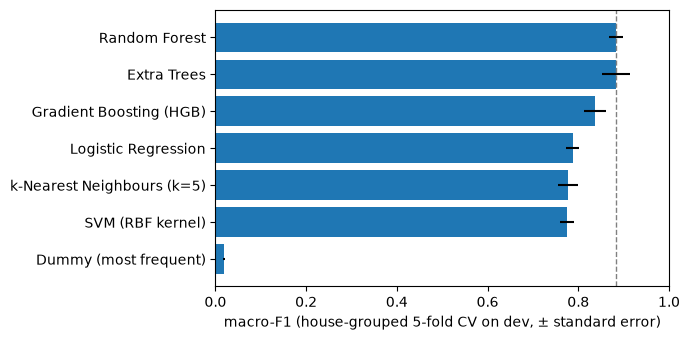

In [2]:
import time
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier

imp = lambda: SimpleImputer(strategy="median")
models = {
    "Dummy (most frequent)": make_pipeline(imp(), DummyClassifier(strategy="most_frequent")),
    "Logistic Regression": make_pipeline(imp(), StandardScaler(), LogisticRegression(max_iter=5000)),
    "k-Nearest Neighbours (k=5)": make_pipeline(imp(), StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "SVM (RBF kernel)": make_pipeline(imp(), StandardScaler(), SVC()),
    "Random Forest": make_pipeline(imp(), RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1)),
    "Extra Trees": make_pipeline(imp(), ExtraTreesClassifier(n_estimators=300, random_state=0, n_jobs=-1)),
    "Gradient Boosting (HGB)": make_pipeline(imp(), HistGradientBoostingClassifier(random_state=0)),
}

rows = []
for name, model in models.items():
    t0 = time.perf_counter()
    rows.append({"model": name, **evaluate(model), "seconds": round(time.perf_counter() - t0, 1)})
results = pd.DataFrame(rows).sort_values("macro_f1", ascending=False).reset_index(drop=True)
display(results)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(results["model"], results["macro_f1"], xerr=results["f1_se"], color="tab:blue")
ax.axvline(results.loc[0, "macro_f1"], ls="--", c="grey", lw=1)
ax.invert_yaxis(); ax.set_xlim(0, 1)
ax.set_xlabel("macro-F1 (house-grouped 5-fold CV on dev, ± standard error)")
plt.tight_layout(); plt.show()

,perm_mean,perm_std,gini_mean,perm_rank,gini_rank
inrush_ratio,0.0415,0.0198,0.0514,1,6
hf_noise_ratio,0.0386,0.0342,0.0635,2,3
transient_energy,0.0226,0.0150,0.0495,3,9
vi_mid_slope,0.0221,0.0187,0.0482,4,10
p_w,0.0143,0.0144,0.0535,5,5
h3_h1,0.0143,0.0126,0.0749,6,2
conduction_angle,0.0093,0.0101,0.0314,7,18
dpf,0.0073,0.0089,0.0455,8,11
i_peak,0.0067,0.0218,0.0540,9,4
vi_area,0.0050,0.0070,0.0413,10,14


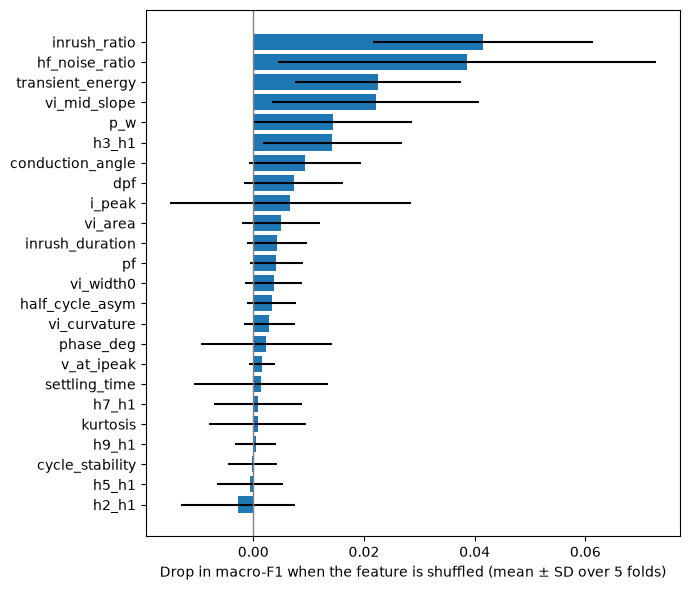

In [3]:
from sklearn.inspection import permutation_importance

rf = make_pipeline(SimpleImputer(strategy="median"),
                   RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1))
perm, gini = [], []
for tr, va in cv.split(X_dev, y_dev, g_dev):
    rf.fit(X_dev.iloc[tr], y_dev.iloc[tr])
    r = permutation_importance(rf, X_dev.iloc[va], y_dev.iloc[va], scoring="f1_macro",
                               n_repeats=10, random_state=0, n_jobs=-1)
    perm.append(r.importances_mean)                 # drop in macro-F1 on unseen homes
    gini.append(rf[-1].feature_importances_)        # RF's built-in importance, for comparison

imp = pd.DataFrame({"perm_mean": np.mean(perm, axis=0), "perm_std": np.std(perm, axis=0, ddof=1),
                    "gini_mean": np.mean(gini, axis=0)}, index=FEATS).sort_values("perm_mean", ascending=False)
imp["perm_rank"] = range(1, len(imp) + 1)
imp["gini_rank"] = imp["gini_mean"].rank(ascending=False).astype(int)
ranking = imp.index.tolist()                         # used in step 4
display(imp.round(4))

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(imp.index, imp["perm_mean"], xerr=imp["perm_std"], color="tab:blue")
ax.axvline(0, c="grey", lw=1); ax.invert_yaxis()
ax.set_xlabel("Drop in macro-F1 when the feature is shuffled (mean ± SD over 5 folds)")
plt.tight_layout(); plt.show()

Best k = 24 (0.886 ± 0.011) | one-SE threshold = 0.875 | one-SE choice: k = 13


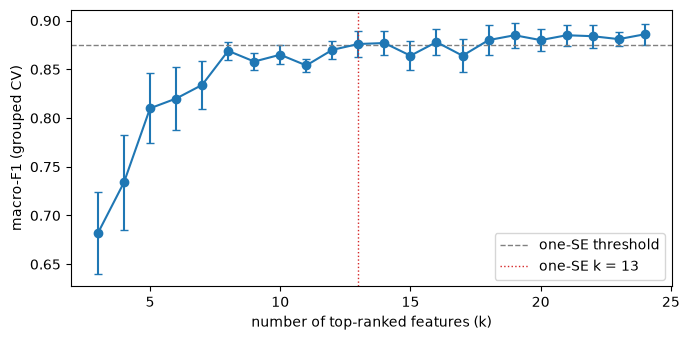

,top 10,top 13,top 15,top 20,top 24
CV seed,,,,,
1,0.862,0.877,0.869,0.879,0.878
2,0.863,0.879,0.871,0.880,0.893
3,0.865,0.876,0.864,0.880,0.886
4,0.848,0.871,0.884,0.875,0.891
5,0.861,0.880,0.880,0.864,0.880


Change vs all 24 (mean over 5 seeds): {'top 10': -0.026, 'top 13': -0.009, 'top 15': -0.012, 'top 20': -0.01, 'top 24': 0.0}
20 final features | dropped: ['cycle_stability', 'h2_h1', 'h5_h1', 'h9_h1']


In [4]:
# 4a. Top-k curve: retrain with the top 3, 4, ..., 24 features (same folds as before)
curve = pd.DataFrame([{"k": k, **evaluate(rf, ranking[:k])}
                      for k in range(3, len(ranking) + 1)]).set_index("k")
best_k = curve["macro_f1"].idxmax()
threshold = curve.loc[best_k, "macro_f1"] - curve.loc[best_k, "f1_se"]
one_se_k = int(curve.index[curve["macro_f1"] >= threshold].min())
print(f"Best k = {best_k} ({curve.loc[best_k, 'macro_f1']:.3f} ± {curve.loc[best_k, 'f1_se']:.3f}) "
      f"| one-SE threshold = {threshold:.3f} | one-SE choice: k = {one_se_k}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.errorbar(curve.index, curve["macro_f1"], yerr=curve["f1_se"], marker="o", capsize=3)
ax.axhline(threshold, ls="--", c="grey", lw=1, label="one-SE threshold")
ax.axvline(one_se_k, ls=":", c="tab:red", lw=1, label=f"one-SE k = {one_se_k}")
ax.set_xlabel("number of top-ranked features (k)"); ax.set_ylabel("macro-F1 (grouped CV)")
ax.legend(); plt.tight_layout(); plt.show()

# 4b. Robustness: do the candidates hold up when different homes land in the folds?
rows = []
for seed in range(1, 6):
    cv_s = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    rows.append({f"top {k}": cross_validate(rf, X_dev[ranking[:k]], y_dev, groups=g_dev, cv=cv_s,
                                           scoring="f1_macro")["test_score"].mean()
                 for k in (10, one_se_k, 15, 20, 24)})
robust = pd.DataFrame(rows, index=pd.Index(range(1, 6), name="CV seed"))
display(robust.round(3))
print("Change vs all 24 (mean over 5 seeds):",
      robust.sub(robust["top 24"], axis=0).mean().round(3).to_dict())

# 4c. Decision (read 4a + 4b first)
FINAL = ranking[:20]
print(len(FINAL), "final features | dropped:", [f for f in FEATS if f not in FINAL])

In [5]:
from sklearn.model_selection import GridSearchCV

grid = {"max_features": ["sqrt", 0.3, 0.5],      # features tried at each split
        "min_samples_leaf": [1, 2, 4],           # smallest leaf size (higher = smoother trees)
        "class_weight": [None, "balanced"]}      # "balanced" up-weights small classes
cands = {"Random Forest": RandomForestClassifier(n_estimators=500, random_state=0),
         "Extra Trees": ExtraTreesClassifier(n_estimators=500, random_state=0)}

best = {}
for name, est in cands.items():
    pipe = make_pipeline(SimpleImputer(strategy="median"), est)
    step = pipe.steps[-1][0]                                  # e.g. "randomforestclassifier"
    gs = GridSearchCV(pipe, {f"{step}__{k}": v for k, v in grid.items()},
                      cv=cv, scoring="f1_macro", n_jobs=-1)
    gs.fit(X_dev[FINAL], y_dev, groups=g_dev)
    res = pd.DataFrame(gs.cv_results_)
    res["se"] = res["std_test_score"] / np.sqrt(cv.get_n_splits())
    top = res.sort_values("rank_test_score").head(5)
    top = top[[c for c in res if c.startswith("param_")] + ["mean_test_score", "se"]]
    top.columns = [c.split("__")[-1] for c in top.columns]
    print(f"{name}: best macro-F1 {gs.best_score_:.3f}"); display(top.round(3))
    best[name] = gs.best_estimator_

# Robustness: do the winners still win when different homes land in the folds?
default = make_pipeline(SimpleImputer(strategy="median"),
                        RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1))
contenders = {"RF default": default, "RF tuned": best["Random Forest"], "ET tuned": best["Extra Trees"]}
rows = []
for seed in range(1, 6):
    cv_s = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    rows.append({n: cross_validate(m, X_dev[FINAL], y_dev, groups=g_dev, cv=cv_s,
                                   scoring="f1_macro", n_jobs=-1)["test_score"].mean()
                 for n, m in contenders.items()})
robust5 = pd.DataFrame(rows, index=pd.Index(range(1, 6), name="CV seed"))
display(robust5.round(3))
print("Change vs RF default (mean over 5 seeds):",
      robust5.sub(robust5["RF default"], axis=0).mean().round(3).to_dict())

Random Forest: best macro-F1 0.885


,class_weight,max_features,min_samples_leaf,mean_test_score,se
10,balanced,sqrt,2,0.885,0.008
0,NaN,sqrt,1,0.882,0.011
9,balanced,sqrt,1,0.880,0.010
1,NaN,sqrt,2,0.873,0.011
13,balanced,0.3,2,0.871,0.012


Extra Trees: best macro-F1 0.877


,class_weight,max_features,min_samples_leaf,mean_test_score,se
17,balanced,0.5,4,0.877,0.025
16,balanced,0.5,2,0.876,0.025
12,balanced,0.3,1,0.875,0.024
8,NaN,0.5,4,0.873,0.023
3,NaN,0.3,1,0.872,0.025


,RF default,RF tuned,ET tuned
CV seed,,,
1,0.879,0.871,0.858
2,0.880,0.880,0.860
3,0.880,0.885,0.877
4,0.875,0.873,0.871
5,0.864,0.874,0.870


Change vs RF default (mean over 5 seeds): {'RF default': 0.0, 'RF tuned': 0.001, 'ET tuned': -0.008}


,precision,recall,f1-score,support
Air Conditioner,0.803,0.808,0.805,151.0
Compact Fluorescent Lamp,0.957,0.968,0.962,185.0
Fan,0.829,0.865,0.847,185.0
Fridge,0.901,0.880,0.890,83.0
Hairdryer,0.864,0.944,0.902,196.0
Heater,0.817,0.690,0.748,71.0
Incandescent Light Bulb,0.969,0.992,0.981,128.0
Laptop,0.903,0.920,0.911,162.0
Microwave,0.993,0.943,0.968,159.0
Vacuum,0.986,1.000,0.993,68.0


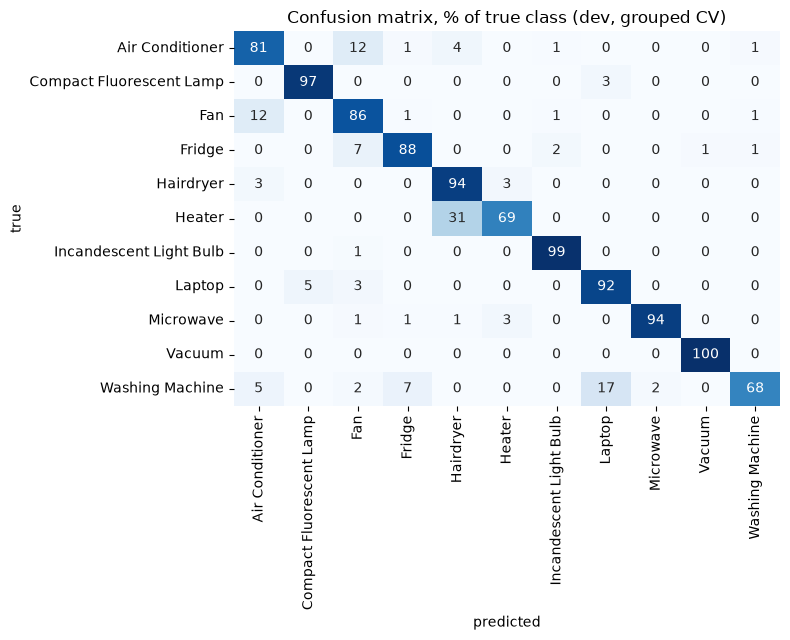

145 errors out of 1447


,true,predicted,count,% of true class
0,Fan,Air Conditioner,22,11.9
1,Heater,Hairdryer,22,31.0
2,Air Conditioner,Fan,18,11.9
3,Washing Machine,Laptop,10,16.9
4,Laptop,Compact Fluorescent Lamp,8,4.9
5,Hairdryer,Heater,6,3.1
6,Air Conditioner,Hairdryer,6,4.0
7,Compact Fluorescent Lamp,Laptop,6,3.2
8,Fridge,Fan,6,7.2
9,Microwave,Heater,5,3.1


,accuracy,recordings
location,,
house41,0.500,10
house55,0.706,17
house21,0.708,24
house18,0.714,7
house30,0.750,16
house24,0.750,20
house51,0.762,21
house3,0.788,80


State-flagged: 15.9% of errors vs 3.1% of correct predictions


In [7]:
import seaborn as sns
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

model = make_pipeline(SimpleImputer(strategy="median"),
                      RandomForestClassifier(n_estimators=500, random_state=0, n_jobs=-1))
pred = pd.Series(cross_val_predict(model, X_dev[FINAL], y_dev, groups=g_dev, cv=cv), index=y_dev.index)

# 6a. Per-class scores
display(pd.DataFrame(classification_report(y_dev, pred, output_dict=True)).T.round(3))

# 6b. Confusion matrix (each row = where that true class went, in %)
labels = sorted(y_dev.unique())
cm = pd.DataFrame(confusion_matrix(y_dev, pred, labels=labels), index=labels, columns=labels)
plt.figure(figsize=(8, 6.5))
sns.heatmap(cm.div(cm.sum(axis=1), axis=0) * 100, annot=True, fmt=".0f", cmap="Blues", cbar=False)
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("Confusion matrix, % of true class (dev, grouped CV)")
plt.tight_layout(); plt.show()

# 6c. Top confusion pairs (.dropna() removes the hidden diagonal; pandas 3 keeps NaN in .stack())
off = cm.where(~np.eye(len(labels), dtype=bool)).stack().dropna().astype(int)
pairs = off[off > 0].sort_values(ascending=False).rename("count").rename_axis(["true", "predicted"]).reset_index()
pairs["% of true class"] = (100 * pairs["count"] / pairs["true"].map(cm.sum(axis=1))).round(1)
print(f"{int((pred != y_dev).sum())} errors out of {len(y_dev)}")
display(pairs.head(10))

# 6d. Hardest homes
home = (pred == y_dev).groupby(g_dev).agg(["mean", "size"]).rename(columns={"mean": "accuracy", "size": "recordings"})
display(home.sort_values("accuracy").head(8).round(3))

# 6e. Are errors linked to the state flags from 03?
state = dev[["flag_low_state", "flag_low_amp"]].any(axis=1)
print(f"State-flagged: {state[pred != y_dev].mean():.1%} of errors vs {state[pred == y_dev].mean():.1%} of correct predictions")

State-flagged dev rows: 63 | features without transient: 16


type,Air Conditioner,Compact Fluorescent Lamp,Fan,Fridge,Hairdryer,Heater,Incandescent Light Bulb,Laptop,Microwave,Vacuum,Washing Machine
flagged rows,0,15,0,8,5,0,0,5,2,10,18


,"baseline (20 features, all rows)",test 1: train without flagged rows,test 2: without 4 transient features
CV seed,,,
0,0.882,0.861,0.784
1,0.883,0.852,0.792
2,0.887,0.864,0.786
3,0.882,0.861,0.784
4,0.879,0.860,0.790
5,0.873,0.862,0.789


Mean change vs baseline: {'test 1: train without flagged rows': -0.021, 'test 2: without 4 transient features': -0.093} | SD: {'test 1: train without flagged rows': 0.006, 'test 2: without 4 transient features': 0.007}


,F1 with transient,F1 without,change,% transient NaN
Air Conditioner,0.805,0.535,-0.270,3.0
Fan,0.847,0.595,-0.252,8.0
Fridge,0.890,0.752,-0.139,20.0
Washing Machine,0.777,0.645,-0.132,14.0
Incandescent Light Bulb,0.981,0.872,-0.109,3.0
Heater,0.748,0.661,-0.087,8.0
Hairdryer,0.902,0.867,-0.036,3.0
Laptop,0.911,0.888,-0.023,75.0
Compact Fluorescent Lamp,0.962,0.944,-0.018,2.0
Microwave,0.968,0.965,-0.003,2.0


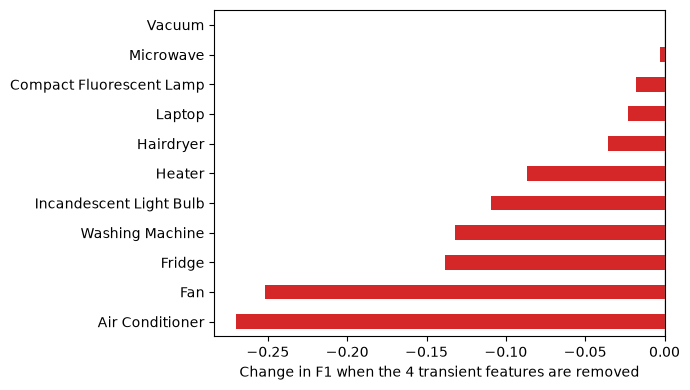

In [8]:
from sklearn.metrics import f1_score

state = dev[["flag_low_state", "flag_low_amp"]].any(axis=1).to_numpy()
TRANSIENT = ["inrush_ratio", "settling_time", "transient_energy", "inrush_duration"]
NO_TR = [f for f in FINAL if f not in TRANSIENT]
print(f"State-flagged dev rows: {state.sum()} | features without transient: {len(NO_TR)}")
display(pd.Series(state, index=dev.index).groupby(dev["type"]).sum().rename("flagged rows").to_frame().T)

def run(cols, drop_flagged_train=False, seed=0):
    """Fold-mean macro-F1 on ALL validation rows; optionally train without state-flagged rows."""
    cv_s = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    scores = []
    for tr, va in cv_s.split(X_dev, y_dev, g_dev):
        if drop_flagged_train:
            tr = tr[~state[tr]]                       # remove flagged rows from TRAINING only
        model.fit(X_dev.iloc[tr][cols], y_dev.iloc[tr])
        scores.append(f1_score(y_dev.iloc[va], model.predict(X_dev.iloc[va][cols]), average="macro"))
    return np.mean(scores)

# 7a + 7b. Both tests on 6 CV seeds
rows = [{"baseline (20 features, all rows)": run(FINAL, seed=s),
         "test 1: train without flagged rows": run(FINAL, drop_flagged_train=True, seed=s),
         "test 2: without 4 transient features": run(NO_TR, seed=s)} for s in range(6)]
sens = pd.DataFrame(rows, index=pd.Index(range(6), name="CV seed"))
display(sens.round(3))
diff = sens.sub(sens.iloc[:, 0], axis=0).iloc[:, 1:]
print("Mean change vs baseline:", diff.mean().round(3).to_dict(), "| SD:", diff.std(ddof=1).round(3).to_dict())

# 7c. Which appliances need the transient features?
p_with = cross_val_predict(model, X_dev[FINAL], y_dev, groups=g_dev, cv=cv)
p_without = cross_val_predict(model, X_dev[NO_TR], y_dev, groups=g_dev, cv=cv)
cls = pd.DataFrame({"F1 with transient": f1_score(y_dev, p_with, average=None, labels=labels),
                    "F1 without": f1_score(y_dev, p_without, average=None, labels=labels)}, index=labels)
cls["change"] = cls["F1 without"] - cls["F1 with transient"]
cls["% transient NaN"] = (dev["inrush_ratio"].isna().groupby(dev["type"]).mean() * 100).round(0)
cls = cls.sort_values("change")
display(cls.round(3))

ax = cls["change"].plot.barh(figsize=(7, 4), color="tab:red")
ax.axvline(0, c="grey", lw=1)
ax.set_xlabel("Change in F1 when the 4 transient features are removed")
plt.tight_layout(); plt.show()

In [9]:
from sklearn.metrics import f1_score, accuracy_score
from sklearn.model_selection import LeaveOneGroupOut

# 8a. Train the final model on ALL dev homes, predict the 10 locked test homes
model = make_pipeline(SimpleImputer(strategy="median"),
                      RandomForestClassifier(n_estimators=500, random_state=0, n_jobs=-1))
model.fit(X_dev[FINAL], y_dev)
y_pred = pd.Series(model.predict(X_test[FINAL]), index=y_test.index)
print(f"TEST: macro-F1 {f1_score(y_test, y_pred, average='macro'):.3f} | "
      f"accuracy {accuracy_score(y_test, y_pred):.3f}")
display(pd.DataFrame(classification_report(y_test, y_pred, output_dict=True, zero_division=0)).T.round(3))

cm_t = pd.DataFrame(confusion_matrix(y_test, y_pred, labels=labels), index=labels, columns=labels)
off_t = cm_t.where(~np.eye(len(labels), dtype=bool)).stack().dropna().astype(int)
display(off_t[off_t > 0].sort_values(ascending=False).head(6).rename("errors").to_frame())

# 8b. Uncertainty: resample the 10 test homes (bootstrap) -> 95% interval for macro-F1
g_test = test["location"].to_numpy(); homes = np.unique(g_test); rng = np.random.default_rng(0)
boots = []
for _ in range(2000):
    idx = np.concatenate([np.flatnonzero(g_test == h) for h in rng.choice(homes, size=len(homes))])
    yt, yp = y_test.to_numpy()[idx], y_pred.to_numpy()[idx]
    boots.append(f1_score(yt, yp, average="macro", labels=np.unique(yt)))
lo, hi = np.percentile(boots, [2.5, 97.5])
print(f"95% interval for test macro-F1 (resampling homes): {lo:.3f} – {hi:.3f}")

# 8c. Accuracy per test home
display((y_pred == y_test).groupby(test["location"]).mean().round(2).rename("accuracy").to_frame().T)

# 8d. Leave-one-house-out on all 56 homes (pipeline frozen) -> comparable with the papers
X_all, y_all, g_all = features[FINAL], features["type"], features["location"]
p_loho = cross_val_predict(model, X_all, y_all, groups=g_all, cv=LeaveOneGroupOut())
print(f"Leave-one-house-out ({g_all.nunique()} homes): accuracy {accuracy_score(y_all, p_loho):.3f} | "
      f"macro-F1 {f1_score(y_all, p_loho, average='macro'):.3f}")

TEST: macro-F1 0.894 | accuracy 0.890


,precision,recall,f1-score,support
Air Conditioner,0.951,0.736,0.830,53.00
Compact Fluorescent Lamp,1.000,0.778,0.875,45.00
Fan,0.717,0.943,0.815,35.00
Fridge,0.826,0.760,0.792,25.00
Hairdryer,0.943,1.000,0.971,50.00
Heater,1.000,1.000,1.000,14.00
Incandescent Light Bulb,0.893,0.862,0.877,29.00
Laptop,0.769,1.000,0.870,40.00
Microwave,1.000,0.976,0.988,41.00
Vacuum,1.000,1.000,1.000,15.00


errors
Compact Fluorescent Lamp Laptop                       10
Air Conditioner          Fan                           7
                         Fridge                        4
                         Washing Machine               3
Fridge                   Fan                           3
                         Incandescent Light Bulb       3

95% interval for test macro-F1 (resampling homes): 0.715 – 0.934


location,house10,house14,house22,house32,house34,house40,house42,house53,house8,house9
accuracy,0.93,0.91,0.65,1.0,0.96,0.77,0.5,1.0,0.89,0.97


Leave-one-house-out (56 homes): accuracy 0.909 | macro-F1 0.903


In [11]:
import sys
import joblib, sklearn
from datetime import date

# 9a. Deployment model: the same frozen pipeline, now trained on ALL 56 homes (dev + test)
final_model = make_pipeline(SimpleImputer(strategy="median"),
                            RandomForestClassifier(n_estimators=500, random_state=0, n_jobs=-1))
final_model.fit(features[FINAL], features["type"])

bundle = {
    "pipeline": final_model,
    "features": FINAL,
    "classes": list(final_model.classes_),
    "trained_on": f"{len(features)} recordings, {features['location'].nunique()} homes (PLAID submetered)",
    "scores": {   # honest scores come from the dev-trained model, not from this one
        "cv_macro_f1_dev": evaluate(model, FINAL)["macro_f1"],
        "test_macro_f1": round(float(f1_score(y_test, y_pred, average="macro")), 3),
        "test_macro_f1_95ci": [round(float(lo), 3), round(float(hi), 3)],
        "test_accuracy": round(float(accuracy_score(y_test, y_pred)), 3),
        "loho_accuracy": round(float(accuracy_score(y_all, p_loho)), 3),
    },
    "sklearn_version": sklearn.__version__,
    "saved": str(date.today()),
}
joblib.dump(bundle, DATA / "plaid_model.joblib")

# 9b. Self-checks
loaded = joblib.load(DATA / "plaid_model.joblib")
assert (loaded["pipeline"].predict(features[FINAL]) == final_model.predict(features[FINAL])).all()

sys.path.insert(0, str(DATA))
from plaid_features import load_wave, extract_features
for k in features["id"].sample(5, random_state=0):
    f_new = pd.Series(extract_features(*load_wave(DATA / "submetered_new" / f"{k}.csv")))[FINAL].astype(float)
    f_old = features.loc[features["id"] == k, FINAL].iloc[0].astype(float)
    assert np.allclose(f_new, f_old, equal_nan=True), f"feature mismatch for id {k}"

print("✓ model saved and reloads identically")
print("✓ plaid_features.py reproduces features.csv (no training-serving skew)")
display({k: v for k, v in loaded.items() if k != "pipeline"})

✓ model saved and reloads identically
✓ plaid_features.py reproduces features.csv (no training-serving skew)


{'features': ['inrush_ratio',
  'hf_noise_ratio',
  'transient_energy',
  'vi_mid_slope',
  'p_w',
  'h3_h1',
  'conduction_angle',
  'dpf',
  'i_peak',
  'vi_area',
  'inrush_duration',
  'pf',
  'vi_width0',
  'half_cycle_asym',
  'vi_curvature',
  'phase_deg',
  'v_at_ipeak',
  'settling_time',
  'h7_h1',
  'kurtosis'],
 'classes': ['Air Conditioner',
  'Compact Fluorescent Lamp',
  'Fan',
  'Fridge',
  'Hairdryer',
  'Heater',
  'Incandescent Light Bulb',
  'Laptop',
  'Microwave',
  'Vacuum',
  'Washing Machine'],
 'trained_on': '1810 recordings, 56 homes (PLAID submetered)',
 'scores': {'cv_macro_f1_dev': 0.882,
  'test_macro_f1': 0.894,
  'test_macro_f1_95ci': [0.715, 0.934],
  'test_accuracy': 0.89,
  'loho_accuracy': 0.909},
 'sklearn_version': '1.9.1',
 'saved': '2026-11-22'}